# Tendencia polinómica

Se reservan los últimos 24 meses para prueba. Los modelos se ajustan solamente con entrenamiento. La caché registra configuraciones y reutiliza resultados si no cambian los datos, parámetros o dependencias.

In [1]:
%matplotlib inline
import nbimporter
import functions
from pathlib import Path
from forecast_cache import fit_predict_cached, memory

Path("../submission").mkdir(parents=True, exist_ok=True)
df_orig = functions.load_data()
df_orig.head()

,yt_true
date,
1946-01-01,890
1946-02-01,992
1946-03-01,979
1946-04-01,959
1946-05-01,1110


In [2]:
# Parámetros del experimento
config = {"degree": 3, "test_months": 24}
df_orig = functions.add_linear_trend_component(df_orig)
df_orig.head()

,yt_true,trend
date,,
1946-01-01,890,0
1946-02-01,992,1
1946-03-01,979,2
1946-04-01,959,3
1946-05-01,1110,4


In [3]:
# Partición cronológica; sin mezclar el futuro con entrenamiento.
(X_complete, y_complete, X_train, y_train, X_test, y_test) = functions.train_test_split(
    df=df_orig, x_columns=["trend"], y_column="yt_true"
)
print(f"Entrenamiento: {len(X_train)} meses; prueba: {len(X_test)} meses")

Entrenamiento: 228 meses; prueba: 24 meses


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, OneHotEncoder

trend_pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=config["degree"], include_bias=False)),
    ("scaler", MinMaxScaler()),
])
preprocessor = ColumnTransformer([
    ("trend", trend_pipeline, ["trend"]),
])
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

In [5]:
# Primera ejecución: entrenar y cachear; siguientes: reutilizar si no hay cambios.
prediction_column = f"yt_pred_time_trend_{config['degree']}"
pipeline, predictions = fit_predict_cached(
    pipeline, X_train, y_train, X_complete, config
)
df_orig.loc[X_complete.index, prediction_column] = predictions
df_orig[["yt_true", prediction_column]].tail()

,yt_true,yt_pred_time_trend_3
date,,
1966-08-01,6905,5460.748665
1966-09-01,5504,5506.780381
1966-10-01,5457,5553.321710
1966-11-01,5198,5600.375838
1966-12-01,4890,5647.945946


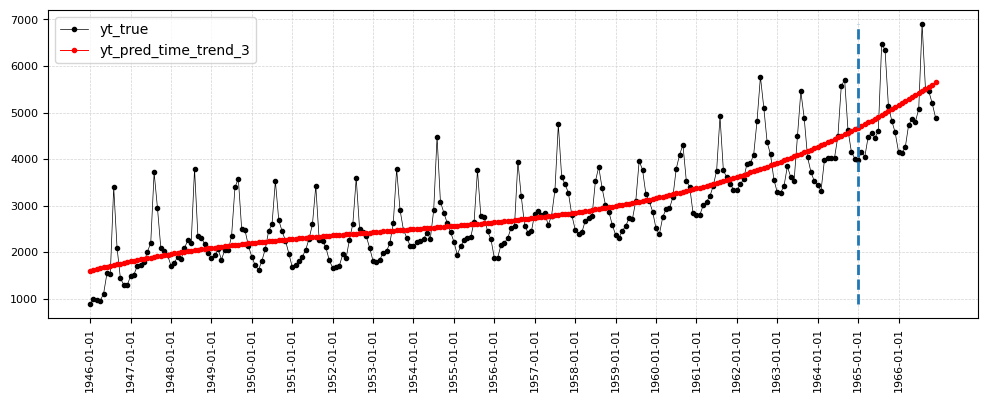

In [6]:
# Gráfica de los pronósticos
functions.plot_time_series(df=df_orig, yt_col="yt_true")

In [7]:
# Métricas sobre las filas con pronóstico; se conservan los últimos 24 meses de prueba.
evaluation = df_orig[["yt_true", prediction_column]].dropna()
metrics = memory.cache(functions.compute_evaluation_metrics)(evaluation)
metrics

,Metrics,yt_pred_time_trend_3
0,MSE Train,337556.42
1,MSE Test,547393.87
2,MAE Train,433.32
3,MAE Test,612.49


In [8]:
# Agregar resultados sin eliminar las columnas de los otros modelos.
functions.save_forecasts(df_orig)
functions.save_metrics(metrics)